# Supervised Learning - Classification de cellules sanguines

- Dataset de **17 092 images RGB** de cellules sanguines périphériques acquises par microscopie.

- **8 classes** : neutrophile, éosinophile, basophile, lymphocyte, monocyte, immature granulocyte, érythroblaste, plaquette.

- Images "annoncées": 360×363px.

- Image acquise avec CellaVision DM96: un analyseur automatisé qui centre automatiquement, standardise le grossissement pour chaque type cellulaire et isole une cellule par image.

Lien: [Dataset Kaggle](https://www.kaggle.com/datasets/unclesamulus/blood-cells-image-dataset/discussion/507729)

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

print('Numpy:', np.__version__)
print('Pandas:', pd.__version__)

Numpy: 2.4.2
Pandas: 3.0.1


In [4]:
DATA_DIR = "../Dataset/bloodcells_dataset"

classes = sorted(os.listdir(DATA_DIR))
print('Classes trouvées :', classes)
print('Nombre de classes :', len(classes))

Classes trouvées : ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Nombre de classes : 8


# EDA :

- Dans les prochains modules nous allons analyser les différents données du dataset afin de comprendre ce que nous allons devoir faire dans le pre-processing des images :

- En premier lieux nous allons regarder la **repartition des classe** dans le dataset.

- Ensuite nous allons étudier **la tailles et la couleur** des images.

- Enfin nous allons voir si il existe des **critères discriminants** au dataset.


# EDA: REPARTITION

basophil: 1218 images
eosinophil: 3117 images
erythroblast: 1551 images
ig: 2895 images
lymphocyte: 1214 images
monocyte: 1420 images
neutrophil: 3329 images
platelet: 2348 images


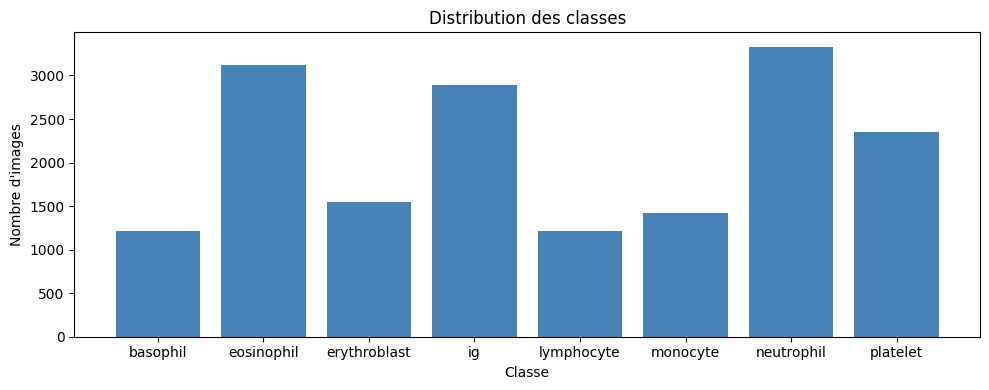

In [126]:
class_counts = {}
for cls in classes:
    class_counts[cls] = len(os.listdir(os.path.join(DATA_DIR, cls)))
    print(f"{cls}: {class_counts[cls]} images")

plt.figure(figsize=(10, 4))
plt.bar(class_counts.keys(), class_counts.values(), color='steelblue')
plt.title('Distribution des classes')
plt.xlabel('Classe')
plt.ylabel("Nombre d'images")
plt.tight_layout()
plt.show()



## Observation sur la repartition

- **unbalanced**: 2 groupes plus ou moins distincts.-> groupe entre 1000 et 1500 samples et autre groupe avec entre 2500 et 3000 samples (*2)

- **weighted loss** ?

# EDA: TAILLE ET COULEURS

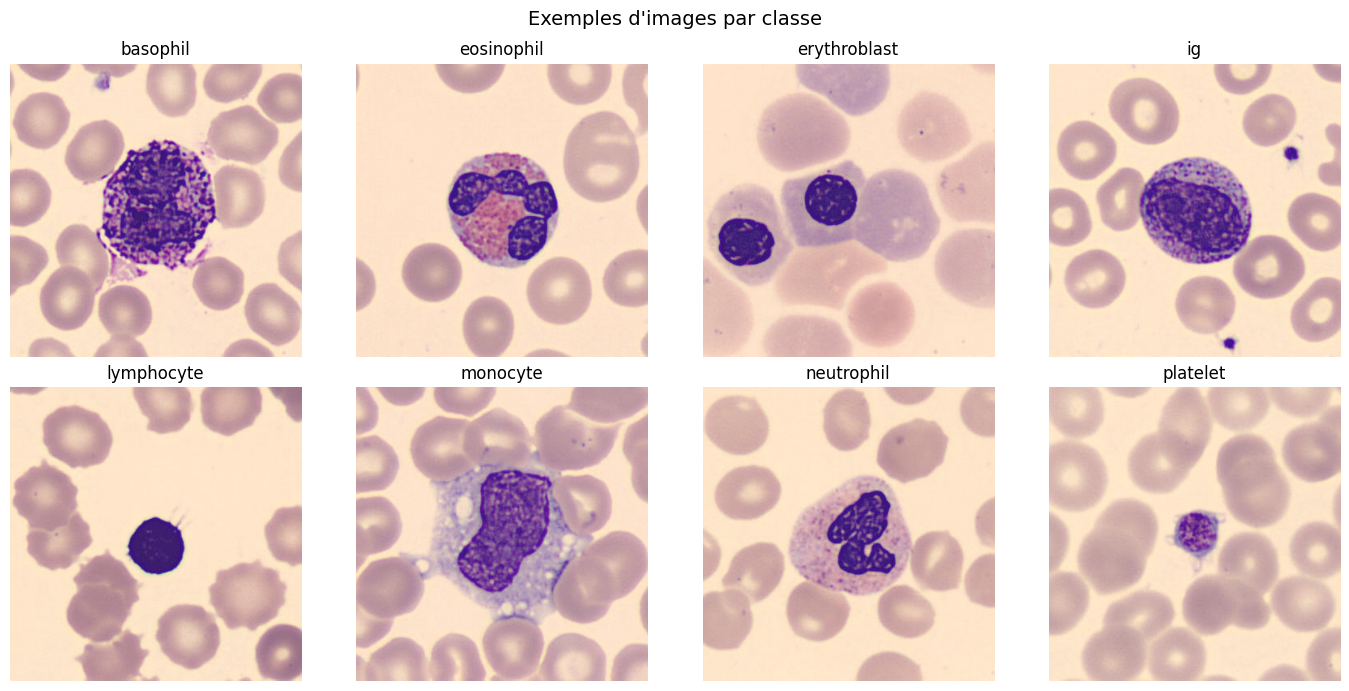

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for i, cls in enumerate(classes):
    img_path = os.path.join(DATA_DIR, cls, os.listdir(os.path.join(DATA_DIR, cls))[0])
    img = Image.open(img_path)
    axes[i].imshow(img)
    axes[i].set_title(cls)
    axes[i].axis('off')

plt.suptitle("Exemples d'images par classe", fontsize=14)
plt.tight_layout()
plt.show()

In [5]:
wrong_sizes = []
wrong_mode = []
first_size = None

for cls in classes:
    cls_dir = os.path.join(DATA_DIR, cls)
    for fname in os.listdir(cls_dir):
        img = Image.open(os.path.join(cls_dir, fname))
        if first_size is None:
            first_size = img.size
        if img.size != first_size:
            wrong_sizes.append(f"{cls}/{fname}: {img.size}")
        if img.mode != 'RGB':
            wrong_mode.append(f"{cls}/{fname}: {img.mode}")

print(f"Taille de référence : {first_size}")
print(f"Images mal dimensionnées : {len(wrong_sizes)}")
print(f"Images non RGB : {len(wrong_mode)}")

if not wrong_sizes and not wrong_mode:
    print("Toutes les images ont la même taille et sont en RGB.")

Taille de référence : (360, 363)
Images mal dimensionnées : 453
Images non RGB : 0


## Observation sur la taille des images :

- on observe que toutes les images n'ont pas la meme dimensions aussi on voit que la taille référence et celle annoncé sur la page du dataset sont trop grosse pour sklearn (plus de **300 par 300 par 3 pixels par image**) sans utiliser un cnn avec pytorch on doit se conformer a une **limite de 64 ou 128 pixels** donc il faudra redimensionner.

- De plus les images sont en couleurs donc **255 valeurs** pour les 3 valeurs de chaque pixels donc on convertie entre 0 et 1 rgb


# EDA: DISCRIMINATION

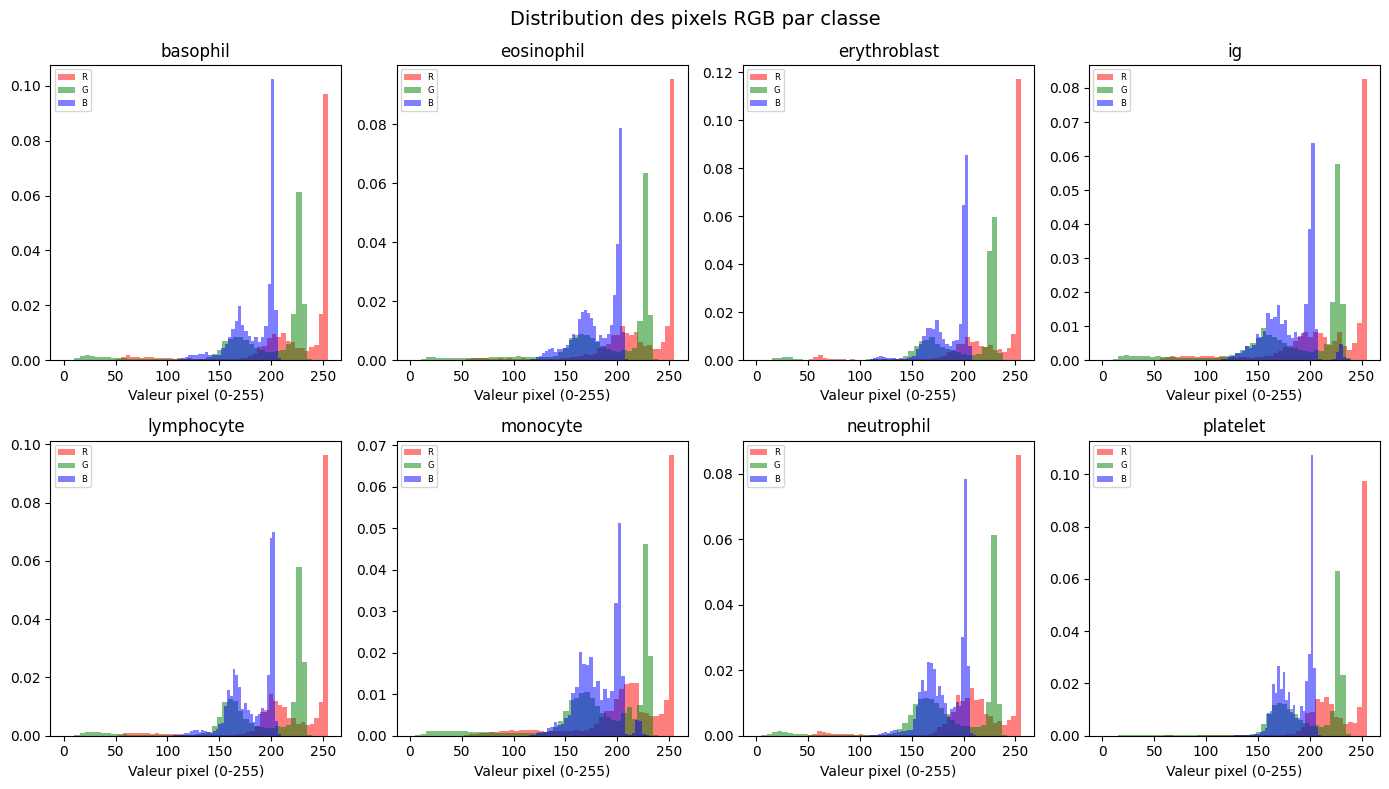

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(14, 8))
axes = axes.flatten()

for i, cls in enumerate(classes):
    cls_dir = os.path.join(DATA_DIR, cls)
    pixels_r, pixels_g, pixels_b = [], [], []

    for fname in os.listdir(cls_dir)[:20]:
        img = np.array(Image.open(os.path.join(cls_dir, fname)))
        pixels_r.extend(img[:, :, 0].flatten())
        pixels_g.extend(img[:, :, 1].flatten())
        pixels_b.extend(img[:, :, 2].flatten())

    axes[i].hist(pixels_r, bins=50, color='red',   alpha=0.5, label='R', density=True)
    axes[i].hist(pixels_g, bins=50, color='green', alpha=0.5, label='G', density=True)
    axes[i].hist(pixels_b, bins=50, color='blue',  alpha=0.5, label='B', density=True)
    axes[i].set_title(cls)
    axes[i].set_xlabel('Valeur pixel (0-255)')
    axes[i].legend(fontsize=6)

plt.suptitle('Distribution des pixels RGB par classe', fontsize=14)
plt.tight_layout()
plt.show()


## Analyse De La Repartition RGB

- On constate que les différents graphe se ressemble et les cellules se confondent aux **bruits généré par le fond blanc commun** a toutes les classes -> on peut sans doute utilise une analyse en Composantes principales **PCA** pour isoler les informations spécifique aux classes (ignorant le fond blanc et ses perturbations)

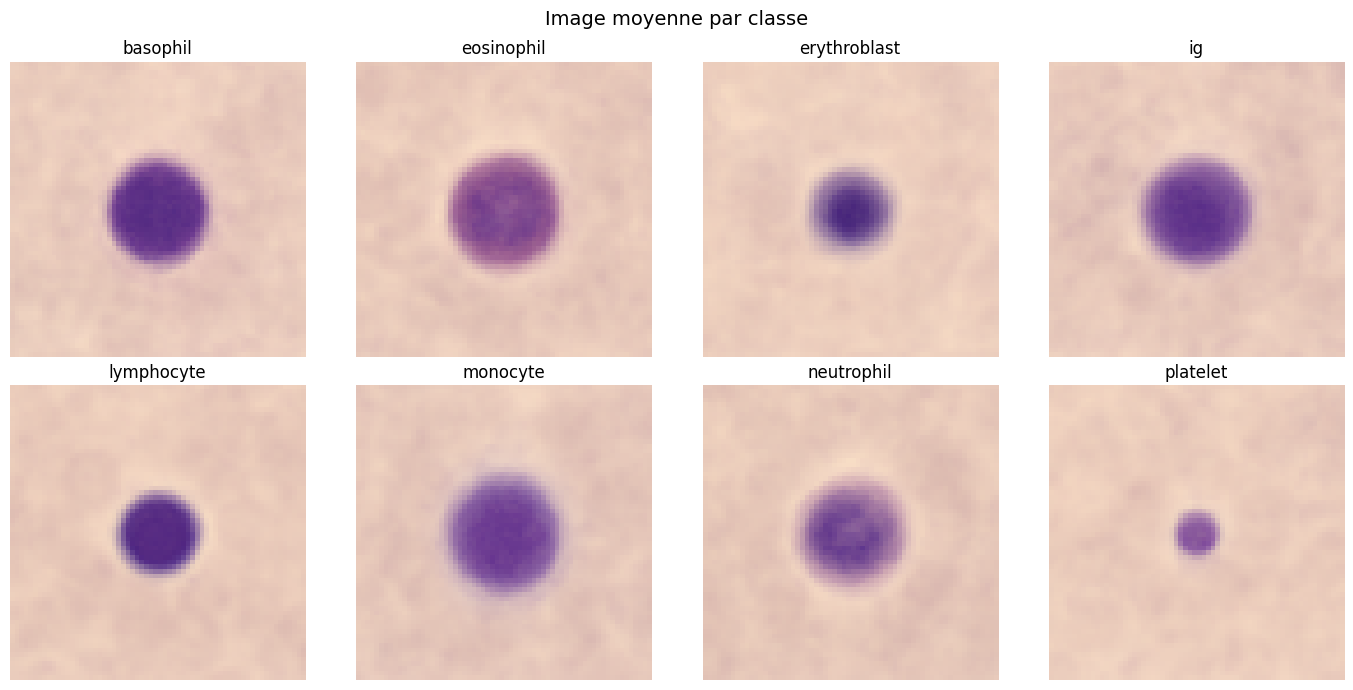

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for i, cls in enumerate(classes):
    cls_dir = os.path.join(DATA_DIR, cls)
    images = []

    for fname in os.listdir(cls_dir)[:50]:
        img = np.array(Image.open(os.path.join(cls_dir, fname)).resize((64, 64)))
        images.append(img)

    mean_img = np.mean(images, axis=0).astype(np.uint8)
    axes[i].imshow(mean_img)
    axes[i].set_title(cls)
    axes[i].axis('off')

plt.suptitle("Image moyenne par classe", fontsize=14)
plt.tight_layout()
plt.show()


## Analyse De l'Image Moyenne Par Classe

- On sait aussi que chaque image est prise avec le meme degrè degrossissement donc la taille est représentative et constitue un facteur discriminant pour les classes.

# PRE-PROCESSING

- Premierement reshape en 64 * 64 et normalisation des valeurs en 255.

In [23]:


def center_crop(img, crop_size=200):
    w, h = img.size
    left = (w - crop_size) // 2
    top = (h - crop_size) // 2
    right = left + crop_size
    bottom = top + crop_size
    return img.crop((left, top, right, bottom))

def apply_circular_mask(img_array):
    h, w = img_array.shape[:2]
    cy, cx = h // 2, w // 2
    radius = min(h, w) // 2
    Y, X = np.ogrid[:h, :w]
    mask = (X - cx)**2 + (Y - cy)**2 <= radius**2
    result = img_array.copy()
    result[~mask] = 0
    return result


X = []
Y = []

for label, cls in enumerate(classes):
    cls_dir = os.path.join(DATA_DIR, cls)
    for fname in os.listdir(cls_dir):
        img = Image.open(os.path.join(cls_dir, fname))
        img = center_crop(img, crop_size=200)
        img = np.array(img.resize((64, 64))) / 255.0
        img = apply_circular_mask(img)
        X.append(img)
        Y.append(label)

X = np.array(X)
Y = np.array(Y)

print(f"X shape: {X.shape}, dtype: {X.dtype}")
print(f"Y shape: {Y.shape}")


X shape: (17092, 64, 64, 3), dtype: float64
Y shape: (17092,)


## Test de cropage

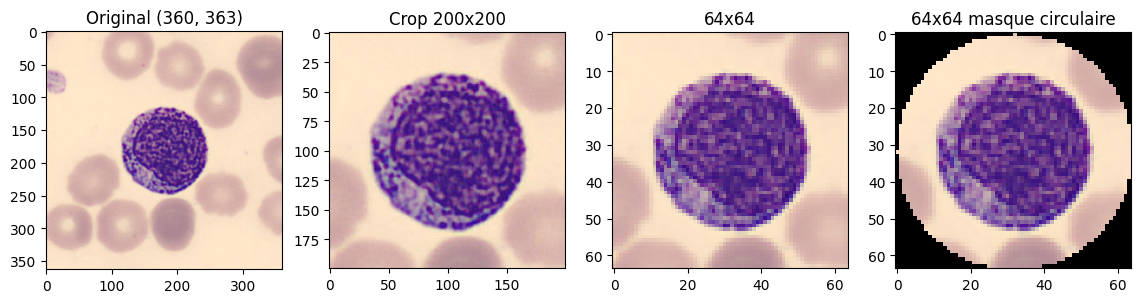

In [115]:
import random

cls = random.choice(classes)
fname = random.choice(os.listdir(os.path.join(DATA_DIR, cls)))
img_test = Image.open(os.path.join(DATA_DIR, cls, fname))

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

axes[0].imshow(img_test)
axes[0].set_title(f"Original {img_test.size}")

cropped = center_crop(img_test, crop_size=200)
axes[1].imshow(cropped)
axes[1].set_title("Crop 200x200")

final = np.array(cropped.resize((64, 64))) / 255.0
axes[2].imshow(final)
axes[2].set_title("64x64")

final_masked = apply_circular_mask(final)
axes[3].imshow(final_masked)
axes[3].set_title("64x64 masque circulaire")

plt.show()




In [28]:
X = []
Y = []

for i, cls in enumerate(classes):
    cls_dir = os.path.join(DATA_DIR, cls)
    for fname in os.listdir(cls_dir):
        img = np.array(Image.open(os.path.join(cls_dir, fname)).resize((64, 64))) / 255.0
        X.append(img)
        Y.append(i)

X = np.array(X) #4 dim
Y = np.array(Y) #1 dim -> N dim img

print(f"X shape: {X.shape}, dtype: {X.dtype}")
print(f"Y shape: {Y.shape}")


KeyboardInterrupt: 

In [42]:
for i, cls in enumerate(classes):
    print(f"{i} -> {cls}")

0 -> basophil
1 -> eosinophil
2 -> erythroblast
3 -> ig
4 -> lymphocyte
5 -> monocyte
6 -> neutrophil
7 -> platelet


## Train_test_split

In [9]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, stratify=Y)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (13673, 64, 64, 3), Test: (3419, 64, 64, 3)


# MODELISATION

- Premierement il faut aplatir des images 4D -> 2D

In [10]:
X_train_flat = X_train.reshape(X_train.shape[0], -1)  # (13673, 12288)
X_test_flat = X_test.reshape(X_test.shape[0], -1)     # (3419, 12288)

print(f"Train flat: {X_train_flat.shape}")
print(f"Test flat: {X_test_flat.shape}")


Train flat: (13673, 12288)
Test flat: (3419, 12288)


## Random Forest model


In [11]:
from sklearn.ensemble import RandomForestClassifier

randforest = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
randforest.fit(X_train_flat, Y_train)

print("Entraînement terminé")


Entraînement terminé


## test du model random forest

In [12]:
from sklearn.metrics import accuracy_score, classification_report

Y_pred = randforest.predict(X_test_flat)

print(f"Accuracy: {accuracy_score(Y_test, Y_pred):.4f}")
print(classification_report(Y_test, Y_pred, target_names=classes))


Accuracy: 0.8628
              precision    recall  f1-score   support

    basophil       0.87      0.60      0.71       244
  eosinophil       0.97      0.96      0.97       623
erythroblast       0.93      0.84      0.88       310
          ig       0.67      0.82      0.73       579
  lymphocyte       0.82      0.85      0.84       243
    monocyte       0.83      0.56      0.67       284
  neutrophil       0.88      0.96      0.92       666
    platelet       0.99      0.99      0.99       470

    accuracy                           0.86      3419
   macro avg       0.87      0.82      0.84      3419
weighted avg       0.87      0.86      0.86      3419



## Analyse des résultats

on constate une bonne performance pour un random forest cependant on observe que il ya des problemes spécifique aux classe :

- on observe que les classe sous représentées dans le dataset sous performe comparé aux autre et on voit des recall faible ce qui veut dire que elle n'ont pas trouvé une grande partie de toutes les images de ce label durant les tests. -> monocyte et basophil

- La classe ig se distingue car elle n'est pas sous-représenté cependant elle est visuellement tres proches des autres classes donc confondu souvent -> ig

- Les lynphocyte eux superforme par rapport au nombre d'image dans le dataset car visuellement plus discriminé que les autres.

il faut donc adapté le training a : ig , mono et baso


In [138]:
randforest = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight='balanced')
randforest.fit(X_train_flat, Y_train)

print("Entraînement terminé")


Entraînement terminé


In [18]:
from sklearn.metrics import accuracy_score, classification_report

Y_pred = randforest.predict(X_test_flat)

print(f"Accuracy: {accuracy_score(Y_test, Y_pred):.4f}")
print(classification_report(Y_test, Y_pred, target_names=classes))


NameError: name 'randforest' is not defined

## test random forest avec weighted balance

- une tres légère amilioration mais insignifiante en raison du manque d'information présente dans les images -> PCA

gain de 0.17 %

# PCA


In [14]:
from sklearn.decomposition import PCA

pca = PCA(n_components=100, random_state=42)
X_train_pca = pca.fit_transform(X_train_flat)
X_test_pca = pca.transform(X_test_flat)

print(f"Train PCA: {X_train_pca.shape}")
print(f"Variance expliquée: {pca.explained_variance_ratio_.sum():.4f}")


KeyboardInterrupt: 

In [27]:
randforest_pca = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight='balanced')
randforest_pca.fit(X_train_pca, Y_train)

Y_pred_pca = randforest_pca.predict(X_test_pca)

print(f"Accuracy: {accuracy_score(Y_test, Y_pred_pca):.4f}")
print(classification_report(Y_test, Y_pred_pca, target_names=classes))


Accuracy: 0.6645
              precision    recall  f1-score   support

    basophil       0.76      0.10      0.18       244
  eosinophil       0.64      0.82      0.72       623
erythroblast       0.80      0.57      0.67       310
          ig       0.48      0.59      0.53       579
  lymphocyte       0.77      0.58      0.66       243
    monocyte       0.82      0.20      0.33       284
  neutrophil       0.60      0.85      0.71       666
    platelet       0.96      0.97      0.97       470

    accuracy                           0.66      3419
   macro avg       0.73      0.59      0.59      3419
weighted avg       0.70      0.66      0.64      3419



on constate que la tantaive est infructueuse malgres le changement de nombre de composant du pca ... 

# Random forest V2 

In [15]:
randforest2 = RandomForestClassifier(
    n_estimators=300,
    max_depth=30,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
randforest2.fit(X_train_flat, Y_train)

Y_pred2 = randforest2.predict(X_test_flat)
print(f"Accuracy: {accuracy_score(Y_test, Y_pred2):.4f}")
print(classification_report(Y_test, Y_pred2, target_names=classes))


Accuracy: 0.8696
              precision    recall  f1-score   support

    basophil       0.84      0.60      0.70       244
  eosinophil       0.97      0.97      0.97       623
erythroblast       0.95      0.85      0.89       310
          ig       0.67      0.82      0.74       579
  lymphocyte       0.85      0.87      0.86       243
    monocyte       0.86      0.61      0.71       284
  neutrophil       0.88      0.95      0.91       666
    platelet       1.00      0.99      0.99       470

    accuracy                           0.87      3419
   macro avg       0.88      0.83      0.85      3419
weighted avg       0.88      0.87      0.87      3419



- on observe un gain de 0.44%

In [17]:
randforest3 = RandomForestClassifier(
    n_estimators=400,
    max_depth=30,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
randforest3.fit(X_train_flat, Y_train)

Y_pred3 = randforest3.predict(X_test_flat)
print(f"Accuracy: {accuracy_score(Y_test, Y_pred3):.4f}")
print(classification_report(Y_test, Y_pred3, target_names=classes))


Accuracy: 0.8725
              precision    recall  f1-score   support

    basophil       0.85      0.66      0.74       244
  eosinophil       0.98      0.96      0.97       623
erythroblast       0.93      0.85      0.89       310
          ig       0.68      0.82      0.74       579
  lymphocyte       0.85      0.87      0.86       243
    monocyte       0.86      0.62      0.72       284
  neutrophil       0.89      0.94      0.91       666
    platelet       1.00      0.99      0.99       470

    accuracy                           0.87      3419
   macro avg       0.88      0.84      0.85      3419
weighted avg       0.88      0.87      0.87      3419



- on observe un gain de 0.18%

## Test avec max feature

In [152]:
rf_final = RandomForestClassifier(n_estimators=300, max_depth=30, min_samples_leaf=2, max_features='sqrt', class_weight='balanced', random_state=42, n_jobs=-1)
rf_final.fit(X_train_flat, Y_train)

print(f"Test Accuracy: {accuracy_score(Y_test, rf_final.predict(X_test_flat)):.4f}")



Test Accuracy: 0.8710


## Matrice de confusion (par rapprot au dernier train)

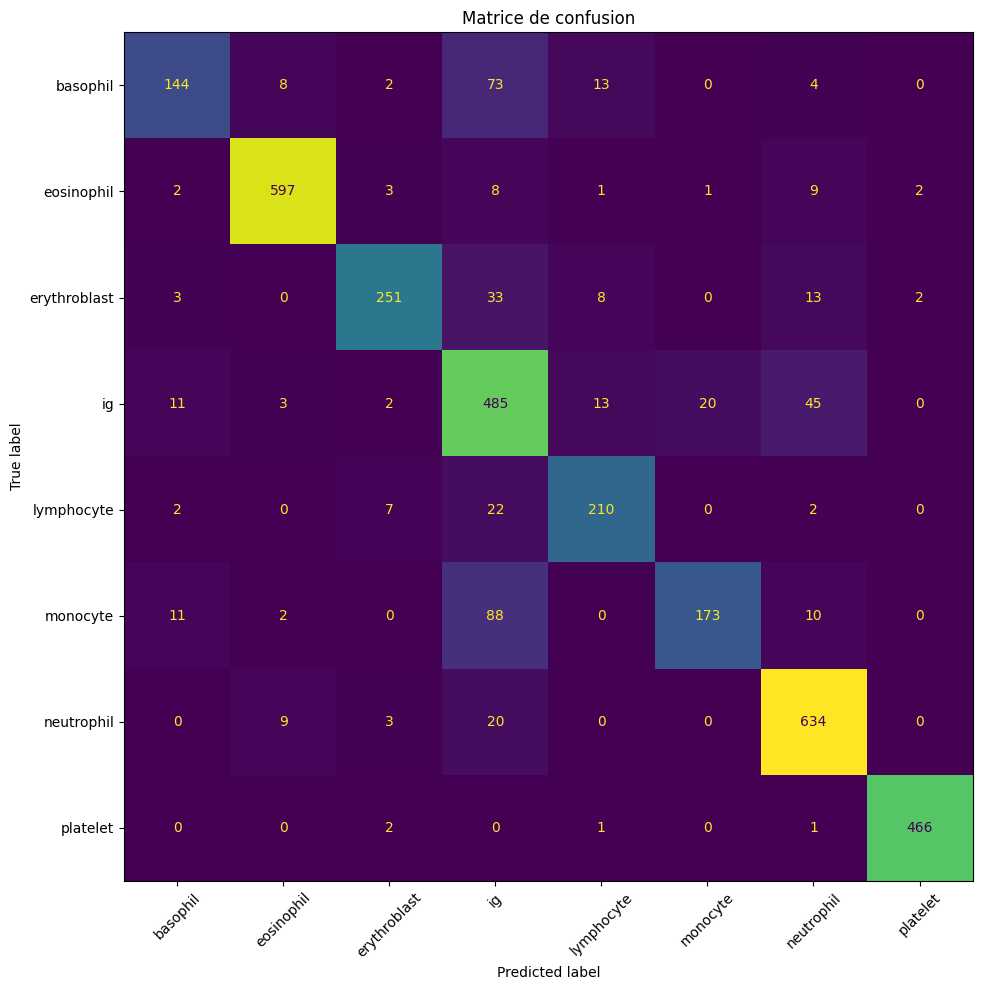

In [117]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(Y_test, Y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Matrice de confusion")
plt.tight_layout()
plt.show()


- on constate bien que se confonde : ig, mono et baso

In [132]:
X = np.array(X)


for test_size in [0.1, 0.2, 0.3]:
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=test_size, random_state=42, stratify=Y)
    X_train_flat = X_train.reshape(X_train.shape[0], -1)
    X_test_flat = X_test.reshape(X_test.shape[0], -1)
    
    rf_tmp = RandomForestClassifier(n_estimators=300, max_depth=30, min_samples_leaf=2, class_weight='balanced', random_state=42, n_jobs=-1)
    rf_tmp.fit(X_train_flat, Y_train)
    
    acc = accuracy_score(Y_test, rf_tmp.predict(X_test_flat))
    print(f"Split {int((1-test_size)*100)}/{int(test_size*100)} → Accuracy: {acc:.4f}")
print(X.shape)
print(X[0][0][0])  # premier pixel - doit avoir des 0 si le masque est appliqué



Split 90/10 → Accuracy: 0.8632
Split 80/20 → Accuracy: 0.8622
Split 70/30 → Accuracy: 0.8654
(17092, 64, 64, 3)
[0. 0. 0.]


## Test avec Fine-tuning

- Test fine tuning sur ig/baso/mono

In [ ]:

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)
X_train, X_val, Y_train, Y_val = train_test_split(X_train, Y_train, test_size=0.125, random_state=42, stratify=Y_train)

print(f"Train: {X_train.shape}")
print(f"Val:   {X_val.shape}")
print(f"Test:  {X_test.shape}")


X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat   = X_val.reshape(X_val.shape[0], -1)
X_test_flat  = X_test.reshape(X_test.shape[0], -1)

for n_est in [100, 200, 300]:
    rf = RandomForestClassifier(n_estimators=n_est, max_depth=30, min_samples_leaf=2, class_weight='balanced', random_state=42, n_jobs=-1)
    rf.fit(X_train_flat, Y_train)
    acc = accuracy_score(Y_val, rf.predict(X_val_flat))
    print(f"n_estimators={n_est} → Val Accuracy: {acc:.4f}")




Train: (11963, 64, 64, 3)
Val:   (1710, 64, 64, 3)
Test:  (3419, 64, 64, 3)
n_estimators=100 → Val Accuracy: 0.8655
n_estimators=200 → Val Accuracy: 0.8643
n_estimators=300 → Val Accuracy: 0.8661


## Identification de ce qui pourrais differentier les confusion 

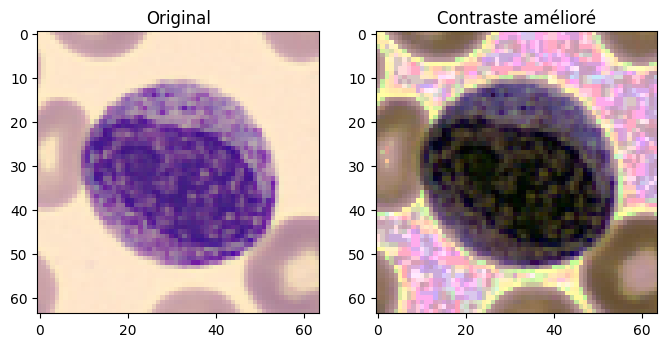

In [157]:
from PIL import ImageOps

img = Image.open(os.path.join(DATA_DIR, 'ig', os.listdir(os.path.join(DATA_DIR, 'ig'))[0]))
cropped = center_crop(img, crop_size=200)
resized = cropped.resize((64, 64))

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(resized)
axes[0].set_title("Original")
axes[1].imshow(ImageOps.equalize(resized))
axes[1].set_title("Contraste amélioré")
plt.show()


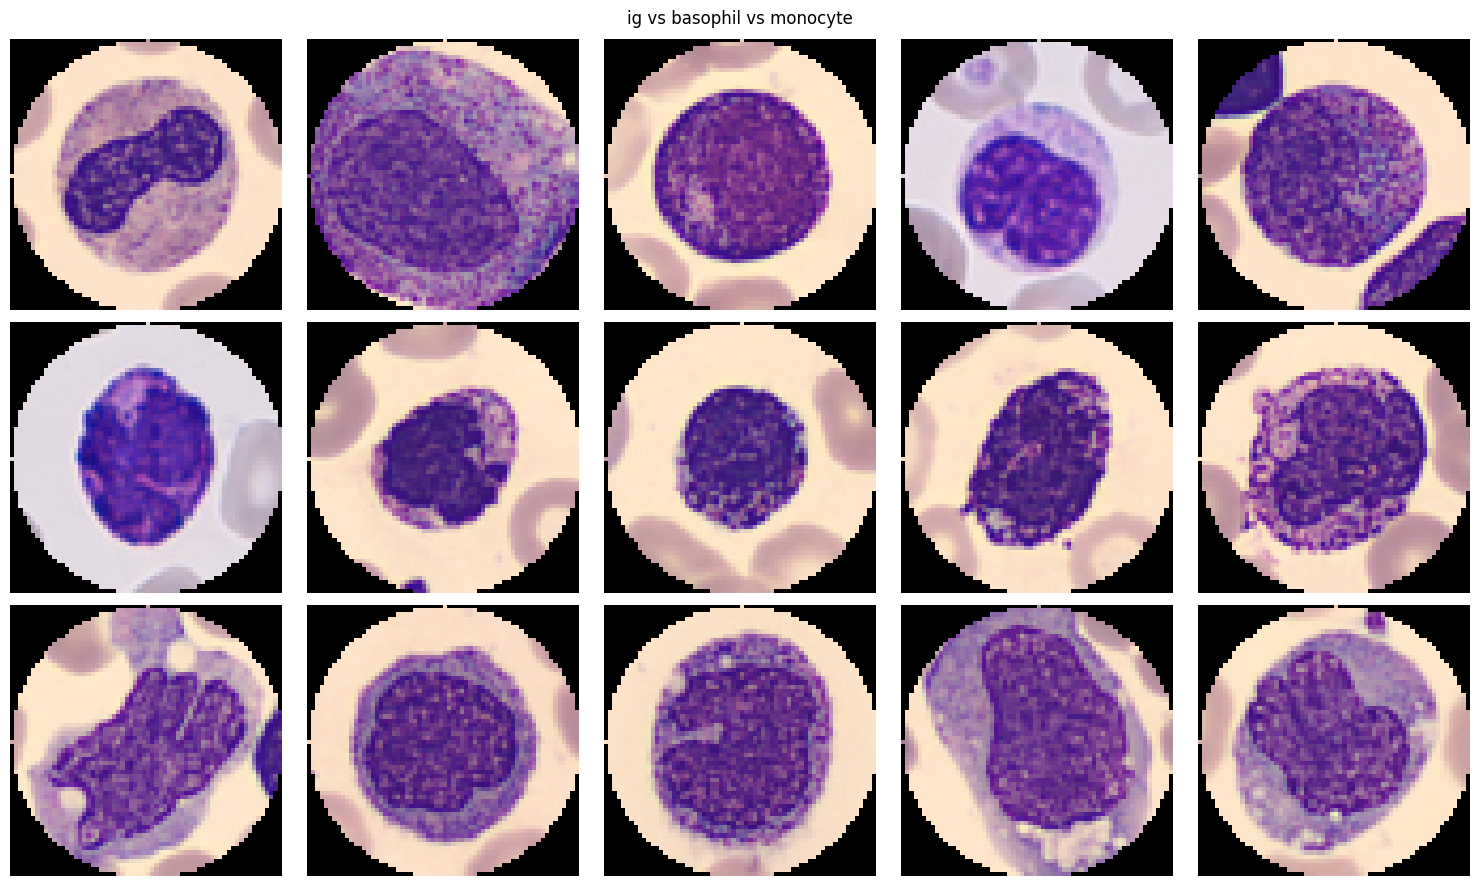

In [156]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for row, cls in enumerate(['ig', 'basophil', 'monocyte']):
    cls_dir = os.path.join(DATA_DIR, cls)
    fnames = random.sample(os.listdir(cls_dir), 5)
    for col, fname in enumerate(fnames):
        img = Image.open(os.path.join(cls_dir, fname))
        cropped = center_crop(img, crop_size=200)
        final = apply_circular_mask(np.array(cropped.resize((64, 64))) / 255.0)
        axes[row][col].imshow(final)
        axes[row][col].axis('off')
    axes[row][0].set_ylabel(cls, fontsize=12)

plt.suptitle("ig vs basophil vs monocyte")
plt.tight_layout()
plt.show()


# TEST EM with clustering of background

## remove background 


In [ ]:
from sklearn.mixture import GaussianMixture

def remove_background_em(img_array, n_components=2):

    h, w, c = img_array.shape
    pixels = img_array.reshape(-1, 3) 

    gmm = GaussianMixture(n_components=n_components, random_state=42, max_iter=50)
    labels = gmm.fit_predict(pixels)

    means_brightness = gmm.means_.mean(axis=1)
    background_label = np.argmax(means_brightness)

    mask = (labels != background_label).reshape(h, w)
    result = img_array.copy()
    result[~mask] = 0.0
    return result


-> on teste ce que ca donne :

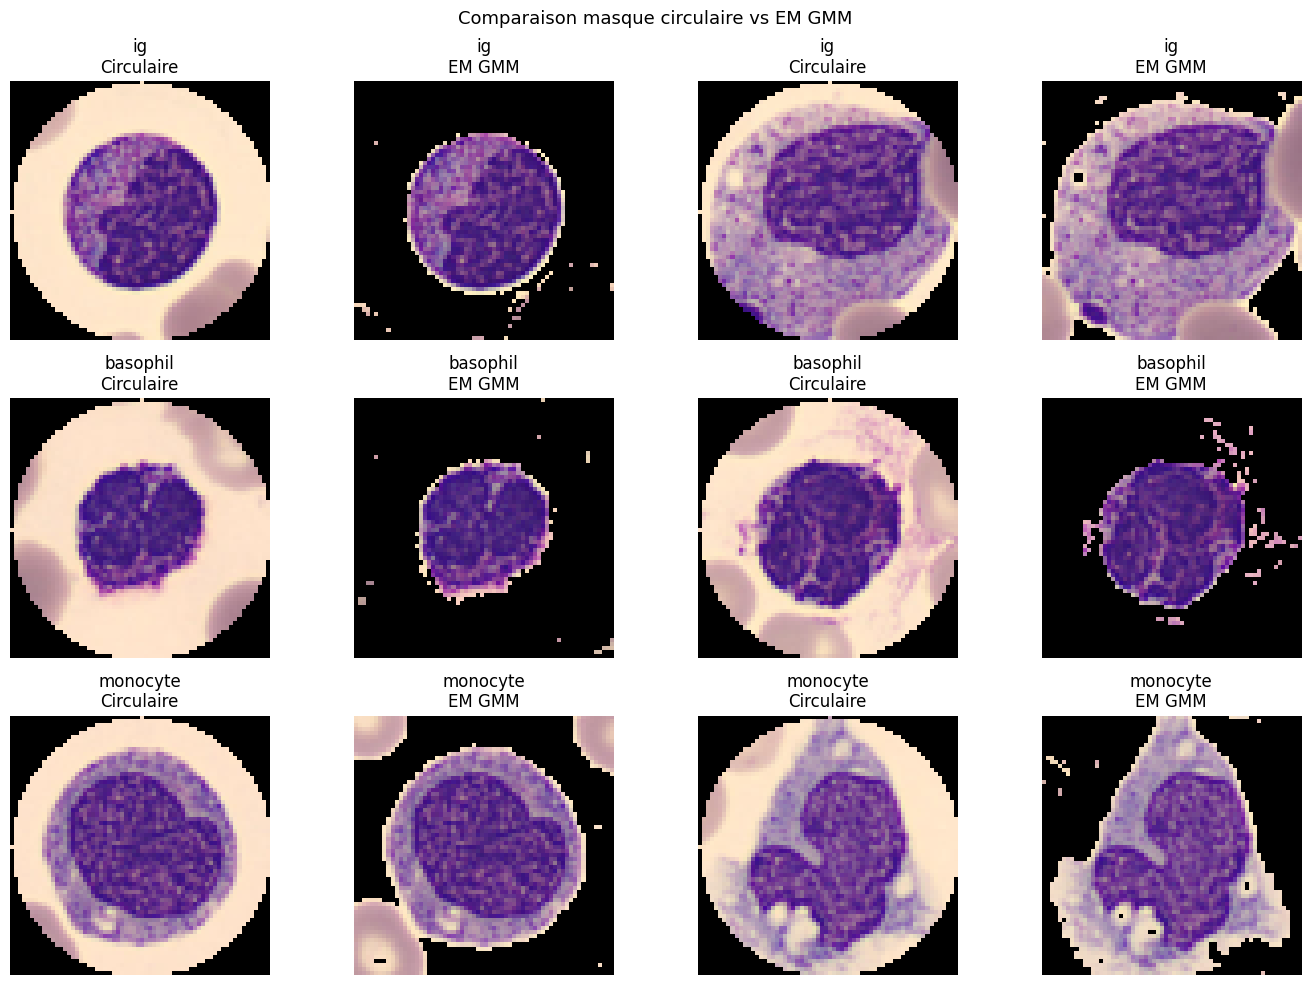

In [ ]:
import random

def center_crop(img, crop_size=200):
    w, h = img.size
    left = (w - crop_size) // 2
    top = (h - crop_size) // 2
    right = left + crop_size
    bottom = top + crop_size
    return img.crop((left, top, right, bottom))

def apply_circular_mask(img_array):
    h, w = img_array.shape[:2]
    cy, cx = h // 2, w // 2
    radius = min(h, w) // 2
    Y, X = np.ogrid[:h, :w]
    mask = (X - cx)**2 + (Y - cy)**2 <= radius**2
    result = img_array.copy()
    result[~mask] = 0
    return result


fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for row, cls in enumerate(['ig', 'basophil', 'monocyte']):
    cls_dir = os.path.join(DATA_DIR, cls)
    fnames = random.sample(os.listdir(cls_dir), 2)

    col = 0
    for fname in fnames:
        img = Image.open(os.path.join(cls_dir, fname))
        cropped = center_crop(img, crop_size=200)
        img_array = np.array(cropped.resize((64, 64))) / 255.0

        masked_circle = apply_circular_mask(img_array)
        masked_em = remove_background_em(img_array)

        axes[row][col].imshow(masked_circle)
        axes[row][col].set_title(f"{cls}\nCirculaire")
        axes[row][col].axis('off')

        axes[row][col + 1].imshow(masked_em)
        axes[row][col + 1].set_title(f"{cls}\nEM GMM")
        axes[row][col + 1].axis('off')

        col += 2

plt.suptitle("Comparaison masque circulaire vs EM GMM", fontsize=13)
plt.tight_layout()
plt.show()


on constate ques les résultat sont plsutot positif meme si il existe quelques petites erreurs ...

# New preprocessing

In [ ]:
from sklearn.mixture import GaussianMixture

def remove_background_em(img_array, n_components=2):
    h, w, c = img_array.shape
    pixels = img_array.reshape(-1, 3)

    gmm = GaussianMixture(
        n_components=n_components,
        covariance_type='diag',
        max_iter=30,
        random_state=42
    )
    labels = gmm.fit_predict(pixels)

    means_brightness = gmm.means_.mean(axis=1)
    background_label = np.argmax(means_brightness)

    mask = (labels != background_label).reshape(h, w)
    result = img_array.copy()
    result[~mask] = 0.0
    return result



In [14]:
X_em = []
Y_em = []

for label, cls in enumerate(classes):
    cls_dir = os.path.join(DATA_DIR, cls)
    for fname in os.listdir(cls_dir):
        img = Image.open(os.path.join(cls_dir, fname))
        img = center_crop(img, crop_size=200)
        img_array = np.array(img.resize((64, 64))) / 255.0
        img_em = remove_background_em(img_array)
        X_em.append(img_em)
        Y_em.append(label)

X_em = np.array(X_em)
Y_em = np.array(Y_em)
print(f"X_em shape: {X_em.shape}")


/home/vanity/delivery/year 2 semestre 1/CVRIE/G-AIA-400-LYN-4-1-cvrie-9/venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/home/vanity/delivery/year 2 semestre 1/CVRIE/G-AIA-400-LYN-4-1-cvrie-9/venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/home/vanity/delivery/year 2 semestre 1/CVRIE/G-AIA-400-LYN-4-1-cvrie-9/venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/home/vanity/delivery/year 2 semestre 1/CVRIE/G-AIA-400-LYN-4-1-cvrie-

X_em shape: (17092, 64, 64, 3)


In [15]:
X_train_em, X_test_em, Y_train_em, Y_test_em = train_test_split(
    X_em, Y_em, test_size=0.2, random_state=42, stratify=Y_em
)
X_train_em_flat = X_train_em.reshape(X_train_em.shape[0], -1)
X_test_em_flat  = X_test_em.reshape(X_test_em.shape[0], -1)

print(f"Train: {X_train_em_flat.shape}, Test: {X_test_em_flat.shape}")


Train: (13673, 12288), Test: (3419, 12288)


In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report


rf_em = RandomForestClassifier(
    n_estimators=400,
    max_depth=30,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_em.fit(X_train_em_flat, Y_train_em)

Y_pred_em = rf_em.predict(X_test_em_flat)
print(f"Accuracy EM GMM : {accuracy_score(Y_test_em, Y_pred_em):.4f}")
print(classification_report(Y_test_em, Y_pred_em, target_names=classes))


Accuracy EM GMM : 0.8298
              precision    recall  f1-score   support

    basophil       0.67      0.63      0.65       244
  eosinophil       0.95      0.97      0.96       623
erythroblast       0.90      0.82      0.86       310
          ig       0.62      0.73      0.67       579
  lymphocyte       0.85      0.81      0.83       243
    monocyte       0.70      0.49      0.57       284
  neutrophil       0.87      0.91      0.89       666
    platelet       0.99      0.99      0.99       470

    accuracy                           0.83      3419
   macro avg       0.82      0.79      0.80      3419
weighted avg       0.83      0.83      0.83      3419



Resultat de cette nouvelle approche :

- on constate que le probleme conerannt ig et la confusion avec les baso et mono est exacerber : les différences sont encores plus frappante entre les résultats des autres classes et les trois précédamment mentionné ...

# Test HOG + MLP classifer

In [5]:
X = []
Y = []

for label, cls in enumerate(classes):
    cls_dir = os.path.join(DATA_DIR, cls)
    for fname in os.listdir(cls_dir):
        img = Image.open(os.path.join(cls_dir, fname))
        img = np.array(img.resize((64, 64))) / 255.0
        X.append(img)
        Y.append(label)

X = np.array(X)
Y = np.array(Y)

print(f"X shape: {X.shape}, dtype: {X.dtype}")
print(f"Y shape: {Y.shape}")


X shape: (17092, 64, 64, 3), dtype: float64
Y shape: (17092,)


In [6]:


from skimage.feature import hog

X_hog = []

for img in X:  # X est déjà chargé (17092, 64, 64, 3)
    features = hog(img, orientations=9, pixels_per_cell=(8, 8),
                   cells_per_block=(2, 2), channel_axis=-1)
    X_hog.append(features)

X_hog = np.array(X_hog)
print(f"X_hog shape: {X_hog.shape}")


X_hog shape: (17092, 1764)


In [7]:
X_train_hog, X_test_hog, Y_train_hog, Y_test_hog = train_test_split(
    X_hog, Y, test_size=0.2, random_state=42, stratify=Y
)
print(f"Train: {X_train_hog.shape}, Test: {X_test_hog.shape}")


Train: (13673, 1764), Test: (3419, 1764)


In [9]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(512, 256),
    activation='relu',
    max_iter=44,
    random_state=42,
    verbose=True
)
mlp.fit(X_train_hog, Y_train_hog)


Iteration 1, loss = 1.41060846
Iteration 2, loss = 1.02212994
Iteration 3, loss = 0.92870409
Iteration 4, loss = 0.89537651
Iteration 5, loss = 0.82478100
Iteration 6, loss = 0.80524442
Iteration 7, loss = 0.74552519
Iteration 8, loss = 0.73390632
Iteration 9, loss = 0.69282437
Iteration 10, loss = 0.66445476
Iteration 11, loss = 0.63605925
Iteration 12, loss = 0.58623189
Iteration 13, loss = 0.56972190
Iteration 14, loss = 0.52466822
Iteration 15, loss = 0.49257841
Iteration 16, loss = 0.44617633
Iteration 17, loss = 0.42373269
Iteration 18, loss = 0.37963328
Iteration 19, loss = 0.34551668
Iteration 20, loss = 0.32254564
Iteration 21, loss = 0.25671574
Iteration 22, loss = 0.21266235
Iteration 23, loss = 0.17579583
Iteration 24, loss = 0.15594530
Iteration 25, loss = 0.12083069
Iteration 26, loss = 0.10042966
Iteration 27, loss = 0.07958471
Iteration 28, loss = 0.05968251
Iteration 29, loss = 0.04192025
Iteration 30, loss = 0.02873216
Iteration 31, loss = 0.02154160
Iteration 32, los

/home/vanity/delivery/year 2 semestre 1/CVRIE/G-AIA-400-LYN-4-1-cvrie-9/venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (44) reached and the optimization hasn't converged yet.
  warnings.warn(


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(512, ...)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",44
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary `.",42


In [12]:
from sklearn.metrics import accuracy_score, classification_report

Y_pred_mlp = mlp.predict(X_test_hog)
print(f"Accuracy HOG+MLP : {accuracy_score(Y_test_hog, Y_pred_mlp):.4f}")
print(classification_report(Y_test_hog, Y_pred_mlp, target_names=classes))


Accuracy HOG+MLP : 0.6449
              precision    recall  f1-score   support

    basophil       0.55      0.49      0.52       244
  eosinophil       0.55      0.74      0.63       623
erythroblast       0.56      0.55      0.56       310
          ig       0.52      0.54      0.53       579
  lymphocyte       0.65      0.56      0.60       243
    monocyte       0.48      0.34      0.40       284
  neutrophil       0.87      0.72      0.79       666
    platelet       0.90      0.89      0.90       470

    accuracy                           0.64      3419
   macro avg       0.63      0.61      0.61      3419
weighted avg       0.66      0.64      0.64      3419



On constate que malgres le traitements avec histogramme de gradients , les résultats ne sont pas dutout convaicant car les couleurs sont bien trop discriminates pour etre ignorée en ne prenant que les bordures avec hog